# Bab 9: Modeling Probabilities and Nonlinearities — Activation Functions

Notebook ini merangkum Bab 9 buku *Grokking Deep Learning* karya Andrew W. Trask. Bab ini membahas **activation function**: fungsi yang diterapkan pada neuron di sebuah layer saat prediksi. Kita sudah memakai satu, yaitu `relu`. Sekarang kita lihat syarat fungsi aktivasi yang baik, pilihan standar untuk hidden layer dan output layer, cara memasangnya dengan benar saat backpropagation, dan mengapa `softmax` cocok untuk klasifikasi.

Isi notebook:

1. Apa itu activation function dan empat syaratnya
2. Fungsi aktivasi standar untuk hidden layer (sigmoid, tanh)
3. Fungsi aktivasi standar untuk output layer (raw, sigmoid, softmax)
4. Masalah inti: input memiliki kemiripan
5. Komputasi softmax
6. Memasang fungsi aktivasi (forward dan backprop)
7. Mengalikan delta dengan slope
8. Mengubah output menjadi slope (turunan)
9. Meng-upgrade network MNIST

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## 1. Apa Itu Activation Function?

Activation function adalah fungsi yang diterapkan pada neuron di sebuah layer selama prediksi. Kita sudah memakai `relu`, yang mengubah semua angka negatif menjadi 0. Secara kasar, activation function adalah fungsi apa pun yang menerima satu angka dan mengembalikan satu angka. Tetapi ada tak hingga banyak fungsi, dan tidak semuanya cocok. Ada empat batasan, dan memakai fungsi di luar batasan ini biasanya ide buruk.

**Syarat 1: Fungsi harus kontinu dan domainnya tak hingga.** Untuk input apa pun harus ada outputnya. Fungsi yang hanya terdefinisi di empat titik akan menjadi activation function yang buruk. Fungsi seperti y = x² baik karena tidak ada x yang tidak punya y.

**Syarat 2: Fungsi yang baik itu monotonik, tidak pernah berubah arah.** Fungsi harus 1:1, selalu naik atau selalu turun. y = x² bukan monotonik, karena hampir setiap nilai y dicapai oleh dua nilai x. y = x selalu naik, jadi baik. Syarat ini secara teknis bukan keharusan: tidak seperti fungsi yang tidak kontinu, fungsi non-monotonik tetap bisa dioptimasi. Tetapi kalau banyak nilai input memetakan ke output yang sama, network punya banyak konfigurasi weight "benar", dan itu justru mempersulit. Seorang optimis akan bilang kemungkinan menemukan jawaban makin besar. Pesimis akan bilang kita kehilangan arah yang jelas untuk mengurangi error, karena dua arah sama-sama bisa tampak berkemajuan. Buku menyebut pandangan pesimis ini lebih penting (topiknya: optimasi konveks vs non-konveks).

**Syarat 3: Fungsi yang baik itu nonlinear (melengkung/berliku).** Ini terkait Bab 6, soal *sometimes correlation* (korelasi kadang-kadang). Agar neuron bisa berkorelasi secara selektif, sinyal negatif dari satu input harus bisa mengurangi seberapa besar neuron itu berkorelasi dengan input lain (misalnya `relu` memaksa neuron jadi 0). Hal itu dimungkinkan oleh fungsi yang melengkung. Fungsi garis lurus hanya mengubah skala weighted sum yang masuk. Mengalikan sesuatu dengan konstanta (misalnya 2) tidak memengaruhi seberapa berkorelasi neuron dengan inputnya, hanya membuat korelasi kolektif jadi lebih keras atau lebih pelan. Yang kita mau adalah korelasi selektif. Contoh: y = 2x + 5 itu linear, sedangkan y = relu(x) nonlinear.

**Syarat 4: Fungsi (dan turunannya) harus efisien dihitung.** Fungsi aktivasi dipanggil berkali-kali, kadang miliaran kali, jadi tidak boleh lambat. Banyak fungsi aktivasi baru populer karena mudah dihitung, walaupun mengorbankan sebagian ekspresivitas (`relu` contohnya).

Berikut gambaran keempat gagasan itu.

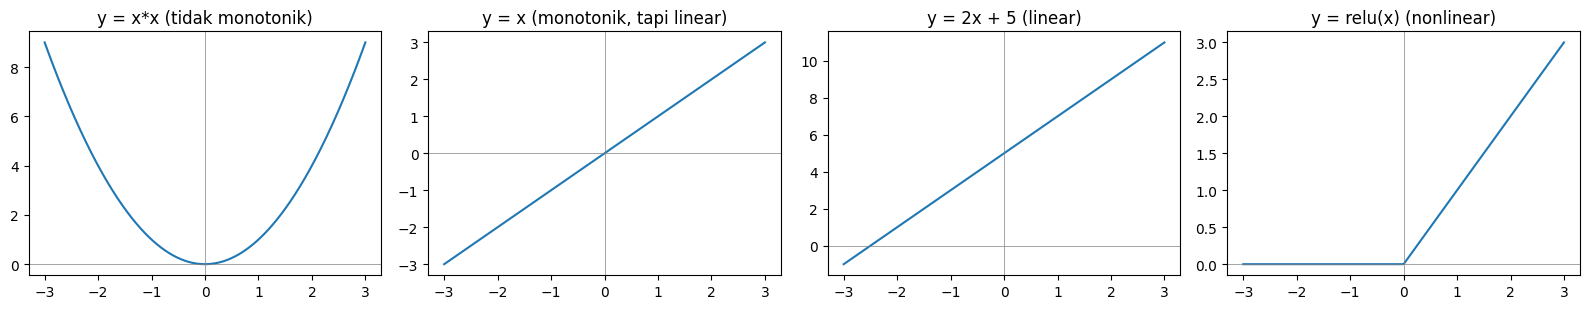

In [2]:
x = np.linspace(-3, 3, 400)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))

# Syarat 2: monotonik vs tidak
axes[0].plot(x, x ** 2)
axes[0].set_title("y = x*x (tidak monotonik)")

axes[1].plot(x, x)
axes[1].set_title("y = x (monotonik, tapi linear)")

# Syarat 3: linear vs nonlinear
axes[2].plot(x, 2 * x + 5)
axes[2].set_title("y = 2x + 5 (linear)")

axes[3].plot(x, np.maximum(0, x))
axes[3].set_title("y = relu(x) (nonlinear)")

for ax in axes:
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
plt.tight_layout()
plt.show()

## 2. Fungsi Aktivasi Standar untuk Hidden Layer

Meski ada tak terhingga fungsi yang memenuhi syarat, daftar yang dipakai untuk mayoritas kebutuhan relatif pendek.

**sigmoid** adalah fungsi andalan. Ia menekan input tak terbatas menjadi output antara 0 dan 1. Pada banyak situasi, ini memungkinkan kita menafsirkan output satu neuron sebagai probabilitas, sehingga sigmoid dipakai di hidden layer maupun output layer.

**tanh** lebih baik dari sigmoid untuk hidden layer. Bentuknya sama seperti sigmoid, tetapi rentangnya −1 sampai 1. Itu berarti ia juga bisa menyumbang **korelasi negatif**. Sigmoid hanya memberi derajat korelasi positif yang bervariasi. Pada banyak masalah, tanh mengungguli sigmoid di hidden layer. Di output layer tanh kurang berguna, kecuali data yang diprediksi memang berada di antara −1 dan 1.

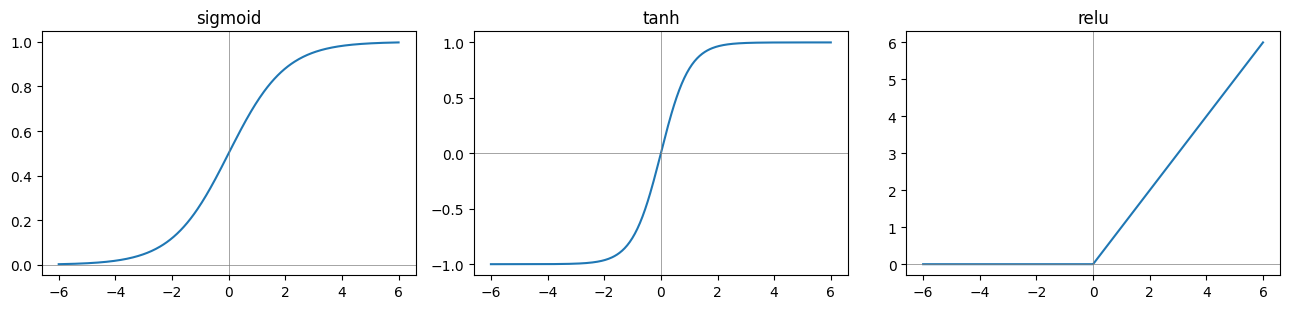

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return (x > 0) * x

x = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for ax, (name, fn) in zip(axes, [("sigmoid", sigmoid), ("tanh", tanh), ("relu", relu)]):
    ax.plot(x, fn(x))
    ax.set_title(name)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
plt.tight_layout()
plt.show()

## 3. Fungsi Aktivasi Standar untuk Output Layer

Fungsi terbaik untuk hidden layer bisa sangat berbeda dari yang terbaik untuk output layer, terutama untuk klasifikasi. Secara garis besar ada tiga jenis output layer.

**Konfigurasi 1: Memprediksi nilai data mentah (tanpa activation function).** Ini yang paling lurus, tetapi paling jarang. Contohnya memprediksi suhu rata-rata di Colorado dari suhu negara bagian di sekitarnya. Rentang outputnya bukan probabilitas, jadi sigmoid atau tanh tidak cocok karena memaksa prediksi berada antara 0 dan 1 (atau −1 dan 1). Di kasus seperti ini, network biasanya dilatih tanpa fungsi aktivasi pada output.

**Konfigurasi 2: Memprediksi probabilitas ya/tidak yang tidak berhubungan (sigmoid).** Sering kita ingin banyak probabilitas biner sekaligus dalam satu network, seperti pada Bab 5: apakah tim menang, apakah ada cedera, dan apakah moral tim senang atau sedih. Saat network punya hidden layer, memprediksi beberapa hal sekaligus bisa menguntungkan: hal yang dipelajari untuk satu label kadang berguna untuk label lain. Di sini sigmoid terbaik karena ia memodelkan probabilitas tiap node output secara terpisah.

**Konfigurasi 3: Memprediksi probabilitas "yang mana" (softmax).** Ini kasus paling umum: memprediksi satu label dari banyak. Pada klasifikasi MNIST, gambar tidak mungkin lebih dari satu angka. Kita bisa melatihnya dengan sigmoid dan memilih probabilitas tertinggi, dan itu cukup berhasil. Tetapi jauh lebih baik memakai fungsi aktivasi yang memodelkan gagasan "makin besar kemungkinan ini label A, makin kecil kemungkinan ini label lain".

Mengapa? Pikirkan bagaimana weight diperbarui. Misalkan gambarnya angka 9 dan weighted sum mentah yang masuk ke layer terakhir adalah 0 untuk semua node kecuali 100 untuk node 9. Itu bisa dibilang sempurna. Lihat apa yang terjadi kalau dilewatkan ke sigmoid dan softmax.

In [4]:
raw = np.array([0., 0., 0., 0., 0., 0., 0., 0., 0., 100.])
target = np.array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

def softmax(x):
    temp = np.exp(x - np.max(x))     # dikurangi max agar stabil secara numerik
    return temp / np.sum(temp)

sig = sigmoid(raw)
soft = softmax(raw)

print("raw     :", raw)
print("sigmoid :", np.round(sig, 2))
print("softmax :", np.round(soft, 2))
print()
print("Error kuadrat (MSE) per node terhadap target:")
print("sigmoid :", np.round((sig - target) ** 2, 2), " total =", np.round(np.sum((sig - target) ** 2), 2))
print("softmax :", np.round((soft - target) ** 2, 2), " total =", np.round(np.sum((soft - target) ** 2), 2))

raw     : [  0.   0.   0.   0.   0.   0.   0.   0.   0. 100.]
sigmoid : [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1. ]
softmax : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]

Error kuadrat (MSE) per node terhadap target:
sigmoid : [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.  ]  total = 2.25
softmax : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]  total = 0.0


Sigmoid memberi 0,50 untuk semua node lain dan 0,99 untuk node 9. Network tampak "ragu", seolah ada peluang 50% itu angka lain. Softmax memberi 1,0 untuk 9 dan 0 untuk yang lain, persis seperti yang kita mau.

Ini bukan sekadar masalah teori. Saat backpropagation, MSE pada output sigmoid menghasilkan error 0,25 untuk tiap node lain, meski prediksinya secara teori hampir sempurna. Network akan menerima pembaruan weight yang besar walaupun sudah memprediksi dengan benar. Untuk mencapai error 0, sigmoid tidak hanya harus memprediksi angka positif tertinggi untuk output yang benar, tetapi juga harus memprediksi 0 di semua tempat lain. Softmax bertanya, "Digit mana yang paling cocok untuk input ini?" Sigmoid berkata, "Yakinlah bahwa ini hanya digit 9 dan tidak punya kesamaan apa pun dengan digit lain."

## 4. Masalah Inti: Input Memiliki Kemiripan

Digit MNIST tidak sepenuhnya berbeda. Nilai pikselnya saling tumpang tindih. Rata-rata digit 2 punya banyak kesamaan dengan rata-rata digit 3 (misalnya lengkungan di bagian atas). Sebagai aturan umum, input yang mirip menghasilkan output yang mirip.

Bayangkan kita forward propagate sebuah gambar 2 dan sedikit probabilitas salah masuk ke label 3. Kalau kesalahan itu dianggap besar dan memicu pembaruan weight besar, network dihukum karena mengenali 2 lewat fitur selain yang eksklusif milik 2. Misalnya dihukum karena mengenali 2 dari lengkungan atas, padahal 3 punya lengkungan yang sama. Akibatnya, sigmoid menghukum network yang mencoba memprediksi 2 dari fitur yang juga dicari untuk 3.

Efek sampingnya: sebagian besar gambar berbagi banyak piksel di tengah, sehingga network mulai berfokus pada tepi. Weight detektor 2 menjadi "keruh" di tengah, dan bobot terbesar ada pada ujung-ujung goresan 2 di dekat tepi gambar. Itu mungkin indikator individual terbaik, tetapi network terbaik melihat bentuk keseluruhan. Indikator tepi mudah terpicu keliru oleh angka 3 yang sedikit bergeser atau miring. Network tidak mempelajari esensi sebuah 2 karena harus belajar 2 dan bukan 1, bukan 3, bukan 4, dan seterusnya.

Kita butuh fungsi aktivasi output yang tidak menghukum label yang mirip, dan memperhatikan semua informasi yang bisa mengindikasikan input mana pun. Softmax juga punya sifat bagus lain: probabilitasnya selalu berjumlah 1, jadi tiap prediksi bisa dibaca sebagai probabilitas global bahwa label itu benar. Softmax bekerja lebih baik, baik dalam teori maupun praktik.

## 5. Komputasi Softmax

Softmax memangkatkan tiap nilai input secara eksponensial lalu membaginya dengan jumlah seluruh layer.

1. Untuk tiap nilai x, hitung eˣ (e ≈ 2,71828). Semua nilai 0 menjadi 1 (karena eˣ bernilai 1 di x = 0), dan 100 menjadi angka raksasa (2 diikuti 43 nol, sekitar 2,688 × 10⁴³). Angka negatif menjadi nilai antara 0 dan 1.
2. Jumlahkan semua node, lalu bagi tiap nilai dengan jumlah itu.

Sifat penting: makin tinggi network memprediksi satu nilai, makin rendah prediksinya untuk yang lain. Ini meningkatkan apa yang disebut *sharpness of attenuation* dan mendorong network memprediksi satu output dengan probabilitas sangat tinggi. Untuk mengatur seberapa agresif efeknya, bisa dipakai angka sedikit lebih besar atau kecil dari e sebagai basis. Namun kebanyakan orang tetap memakai e.

In [5]:
# Langkah demi langkah, persis seperti penjelasan di atas
raw = np.array([0., 0., 0., 0., 0., 0., 0., 0., 0., 100.])

exps = np.exp(raw)                 # langkah 1: e^x
print("e^x     :", exps)
probs = exps / np.sum(exps)        # langkah 2: bagi dengan jumlah
print("softmax :", probs)
print("jumlah  :", probs.sum())

# Contoh yang lebih wajar
logits = np.array([2.0, 1.0, 0.1])
p = np.exp(logits) / np.sum(np.exp(logits))
print()
print("logits  :", logits)
print("softmax :", np.round(p, 3), " jumlah =", p.sum())

e^x     : [1.0000e+00 1.0000e+00 1.0000e+00 1.0000e+00 1.0000e+00 1.0000e+00
 1.0000e+00 1.0000e+00 1.0000e+00 2.6881e+43]
softmax : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
jumlah  : 1.0

logits  : [2.  1.  0.1]
softmax : [0.659 0.242 0.099]  jumlah = 1.0


## 6. Instruksi Memasang Fungsi Aktivasi

Bagaimana memasang fungsi aktivasi favorit ke layer mana pun? Kita sudah pernah melakukannya dengan `relu` di hidden layer network dalam pertama kita. Pada forward propagation, ambil nilai `layer_1` sebelum aktivasi lalu terapkan fungsi ke tiap nilai:

```python
layer_0 = images[i:i+1]
layer_1 = relu(np.dot(layer_0, weights_0_1))
layer_2 = np.dot(layer_1, weights_1_2)
```

Sedikit istilah: **input ke sebuah layer** berarti nilai *sebelum* nonlinearitas. Di sini input ke `layer_1` adalah `np.dot(layer_0, weights_0_1)`. Jangan tertukar dengan *layer sebelumnya* (`layer_0`).

Menambahkan aktivasi di forward propagation mudah. Mengompensasinya di backpropagation lebih berliku. Di Bab 6, kita membuat `layer_1_delta` dengan mengalikan delta di tempat `relu` menghasilkan 0 dengan 0. Alasannya, "nilai `layer_1` sebesar 0 tidak berpengaruh pada prediksi output, jadi tidak boleh berpengaruh pada pembaruan weight." Itu bentuk ekstrem dari sifat yang lebih halus.

Slope `relu` untuk angka positif tepat 1, dan untuk negatif tepat 0. Mengubah input sedikit akan berefek 1:1 jika ia memprediksi positif, dan tidak berefek (0:1) jika negatif. Slope adalah ukuran seberapa besar output berubah akibat perubahan input. Karena tujuan delta adalah memberi tahu layer sebelumnya "buat inputku lebih tinggi/rendah", delta ini berguna: ia memodifikasi delta yang dipropagasi balik dari layer berikutnya dengan memperhitungkan apakah node ini ikut menyumbang error.

Jadi saat backpropagation, untuk membuat `layer_1_delta`, kalikan delta hasil propagasi balik dari `layer_2` dengan slope `relu` pada titik yang diprediksi saat forward propagation:

```python
layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
```

`relu2deriv` adalah fungsi khusus yang menerima *output* `relu` dan menghitung slope-nya di titik itu. Pertanyaannya: bagaimana melakukan penyesuaian serupa untuk nonlinearitas selain `relu`?

## 7. Mengalikan Delta dengan Slope

Untuk menghitung `layer_delta`, kalikan delta yang dipropagasi balik dengan slope layer tersebut.

`layer_1_delta[0]` menyatakan seberapa tinggi atau rendah node hidden pertama di layer 1 seharusnya, supaya error network berkurang (untuk satu contoh training). Kalau tidak ada nonlinearitas, ini adalah rata-rata berbobot delta `layer_2`. Tetapi tujuan akhir delta pada sebuah neuron adalah memberi tahu weight apakah mereka sebaiknya bergerak. Kalau menggerakkannya tidak berefek, weight (sebagai grup) sebaiknya dibiarkan. Ini jelas pada `relu` yang hanya menyala atau mati. Sigmoid lebih bernuansa.

Pada satu neuron sigmoid, sensitivitas terhadap perubahan input naik perlahan saat input mendekati 0 dari arah mana pun. Untuk input sangat positif atau sangat negatif, slope mendekati 0. Artinya, saat input sangat besar atau kecil, perubahan kecil pada weight yang masuk menjadi kurang relevan terhadap error neuron untuk contoh itu. Sebagian besar node hidden tidak relevan untuk memprediksi angka 2 (mungkin hanya dipakai untuk 8), jadi weight-nya jangan diubah banyak-banyak, supaya kegunaannya di tempat lain tidak rusak.

Sebaliknya, ini juga menciptakan "kelengketan": weight yang sudah sering diperbarui ke satu arah (pada contoh yang mirip) memprediksi nilai tinggi atau rendah dengan yakin. Nonlinearitas ini mempersulit contoh training yang sesekali keliru untuk merusak pengetahuan yang sudah diperkuat berkali-kali.

## 8. Mengubah Output Menjadi Slope (Turunan)

Sebagian besar fungsi aktivasi yang hebat bisa mengubah *output*-nya menjadi slope-nya, dan ini kemenangan efisiensi. Alih-alih menghitung turunan pada titik tertentu secara kalkulus biasa, praktik standar di industri memakai output layer saat forward propagation untuk menghitung turunannya.

Berikut tabel fungsi yang sudah kita lihat, beserta turunannya. `input` adalah vektor NumPy (input ke layer), `output` adalah prediksi layer, `deriv` adalah turunan aktivasi di tiap node, dan `true` adalah vektor nilai sebenarnya (biasanya 1 pada posisi label benar dan 0 di tempat lain).

| Fungsi | Forward prop | Backprop delta |
|---|---|---|
| relu | `ones_and_zeros = (input > 0)`<br>`output = input * ones_and_zeros` | `mask = output > 0`<br>`deriv = output * mask` |
| sigmoid | `output = 1 / (1 + np.exp(-input))` | `deriv = output * (1 - output)` |
| tanh | `output = np.tanh(input)` | `deriv = 1 - (output ** 2)` |
| softmax | `temp = np.exp(input)`<br>`output = temp / np.sum(temp)` | `temp = (output - true)`<br>`output = temp / len(true)` |

Perhitungan delta untuk softmax istimewa karena hanya dipakai di layer terakhir. Ada lebih banyak teori di baliknya yang tidak dibahas di sini (terutama kaitannya dengan fungsi error *cross entropy*).

In [6]:
# Fungsi aktivasi beserta turunannya yang dihitung dari OUTPUT
def relu(x):
    return (x >= 0) * x

def relu2deriv(output):
    return output >= 0

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid2deriv(output):
    return output * (1 - output)

def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1 - (output ** 2)

def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)


# Verifikasi: turunan dari output harus sama dengan turunan numerik
x = np.array([-2.0, -0.5, 0.3, 1.5])
eps = 1e-6

for name, f, f2d in [("sigmoid", sigmoid, sigmoid2deriv), ("tanh", tanh, tanh2deriv)]:
    numeric = (f(x + eps) - f(x - eps)) / (2 * eps)
    from_output = f2d(f(x))
    print(f"{name:<8} numerik={np.round(numeric, 5)}  dari output={np.round(from_output, 5)}")

sigmoid  numerik=[0.105  0.235  0.2445 0.1492]  dari output=[0.105  0.235  0.2445 0.1492]
tanh     numerik=[0.0707 0.7864 0.9151 0.1807]  dari output=[0.0707 0.7864 0.9151 0.1807]


## 9. Meng-upgrade Network MNIST

Secara teori, `tanh` seharusnya membuat hidden layer lebih baik, dan `softmax` membuat output layer lebih baik. Memang keduanya mencapai skor lebih tinggi, tetapi tidak sesederhana itu. Penulis harus melakukan beberapa penyesuaian:

- **Inisialisasi weight untuk tanh**: `np.random.random` menghasilkan angka acak 0 sampai 1. Dikali 0,2 lalu dikurangi 0,1 menghasilkan rentang −0,1 sampai 0,1, yang bagus untuk `relu` tetapi kurang optimal untuk `tanh`. `tanh` menyukai inisialisasi yang lebih sempit, jadi diubah ke −0,01 sampai 0,01.
- **Penghitungan error dihapus**: secara teknis softmax paling baik dipakai dengan fungsi error *cross entropy*. Network ini sudah menghitung `layer_2_delta` yang benar untuk ukuran error itu, tetapi karena kita belum membahas mengapa cross entropy menguntungkan, baris penghitungan errornya dihapus.
- **Penyetelan ulang `alpha`**: seperti hampir setiap perubahan pada network, `alpha` harus ditala ulang. Buku memakai `alpha` yang jauh lebih besar (2) agar mencapai skor yang baik dalam 300 iterasi.

Hasil di buku: test accuracy **87%**.

Pertama muat MNIST.

In [7]:
import sys
import numpy as np

np.random.seed(1)

# Memuat MNIST. Buku memakai keras; kalau tidak tersedia, dipakai OpenML lewat scikit-learn.
try:
    from keras.datasets import mnist
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
except Exception:
    from sklearn.datasets import fetch_openml
    mn = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X_all, y_all = mn.data.astype("float64"), mn.target.astype(int)
    x_train, y_train = X_all[:60000], y_all[:60000]
    x_test, y_test = X_all[60000:], y_all[60000:]

# 1000 gambar pertama untuk latihan, seluruh data uji untuk evaluasi
images = x_train[0:1000].reshape(1000, 28 * 28) / 255
labels = y_train[0:1000]

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28 * 28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

print(images.shape, labels.shape, test_images.shape, test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(1000, 784) (1000, 10) (10000, 784) (10000, 10)


In [8]:
alpha, iterations, hidden_size = (2, 300, 100)
pixels_per_image, num_labels = (784, 10)
batch_size = 100

# tanh menyukai inisialisasi yang lebih sempit
weights_0_1 = 0.02 * np.random.random((pixels_per_image, hidden_size)) - 0.01
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

for j in range(iterations):
    correct_cnt = 0

    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))

        layer_0 = images[batch_start:batch_end]
        layer_1 = tanh(np.dot(layer_0, weights_0_1))

        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2

        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            correct_cnt += int(np.argmax(layer_2[k:k+1]) ==
                               np.argmax(labels[batch_start + k:batch_start + k + 1]))

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) \
                        / (batch_size * layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    # Evaluasi pada data uji (tanpa dropout). Untuk argmax, softmax tidak mengubah hasilnya.
    test_correct_cnt = 0
    for i in range(len(test_images)):
        layer_0 = test_images[i:i+1]
        layer_1 = tanh(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)
        test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

    if j % 10 == 0:
        sys.stdout.write("\n" + "I:" + str(j) +
                         " Test-Acc:" + str(test_correct_cnt / float(len(test_images))) +
                         " Train-Acc:" + str(correct_cnt / float(len(images))))


I:0 Test-Acc:0.4113 Train-Acc:0.168
I:10 Test-Acc:0.7043 Train-Acc:0.724
I:20 Test-Acc:0.7176 Train-Acc:0.732
I:30 Test-Acc:0.7414 Train-Acc:0.763
I:40 Test-Acc:0.7712 Train-Acc:0.797
I:50 Test-Acc:0.7972 Train-Acc:0.821
I:60 Test-Acc:0.8123 Train-Acc:0.844
I:70 Test-Acc:0.823 Train-Acc:0.851
I:80 Test-Acc:0.8301 Train-Acc:0.873
I:90 Test-Acc:0.8346 Train-Acc:0.895
I:100 Test-Acc:0.8391 Train-Acc:0.883
I:110 Test-Acc:0.8432 Train-Acc:0.896
I:120 Test-Acc:0.8453 Train-Acc:0.903
I:130 Test-Acc:0.8486 Train-Acc:0.905
I:140 Test-Acc:0.8509 Train-Acc:0.909
I:150 Test-Acc:0.8534 Train-Acc:0.915
I:160 Test-Acc:0.8559 Train-Acc:0.919
I:170 Test-Acc:0.8572 Train-Acc:0.925
I:180 Test-Acc:0.859 Train-Acc:0.924
I:190 Test-Acc:0.8611 Train-Acc:0.921
I:200 Test-Acc:0.8623 Train-Acc:0.927
I:210 Test-Acc:0.863 Train-Acc:0.931
I:220 Test-Acc:0.8635 Train-Acc:0.932
I:230 Test-Acc:0.8646 Train-Acc:0.94
I:240 Test-Acc:0.8654 Train-Acc:0.945
I:250 Test-Acc:0.8662 Train-Acc:0.929
I:260 Test-Acc:0.8669 Trai

Cuplikan hasil di buku: test accuracy naik dari 0,394 (iterasi 0) hingga sekitar 0,87 (iterasi 290), dengan train accuracy sekitar 0,94. Keduanya jauh lebih tinggi daripada network `relu` + tanpa softmax di Bab 8 (sekitar 81–82% pada puncaknya).

Evaluasi test dibiarkan memakai `layer_2` mentah tanpa softmax. Itu tidak masalah untuk menghitung akurasi karena `argmax` dari nilai mentah sama dengan `argmax` dari softmax (softmax monoton).

## Poin-poin Penting Bab 9

- **Activation function** adalah fungsi yang diterapkan pada neuron sebuah layer selama prediksi. Empat syarat fungsi aktivasi yang baik: kontinu dan domain tak hingga, monotonik (disarankan), nonlinear, dan efisien dihitung (beserta turunannya).
- Untuk hidden layer, pilihan standar adalah **sigmoid** (output 0 sampai 1) dan **tanh** (−1 sampai 1, bisa mewakili korelasi negatif sehingga sering lebih baik di hidden layer).
- Untuk output layer ada tiga konfigurasi: tanpa aktivasi (memprediksi nilai mentah), **sigmoid** (beberapa probabilitas ya/tidak yang tidak berhubungan), dan **softmax** (memilih satu label dari banyak).
- **Softmax** memangkatkan tiap nilai dengan e lalu membaginya dengan jumlah. Hasilnya probabilitas yang berjumlah 1 dan tidak menghukum label yang mirip, sehingga cocok untuk klasifikasi seperti MNIST.
- Saat backpropagation, delta layer dikalikan dengan **slope** fungsi aktivasi. Weight yang tidak akan berpengaruh jika diubah dibiarkan. Hampir semua fungsi aktivasi populer bisa menghitung turunannya langsung dari output layer (sigmoid: `out*(1-out)`, tanh: `1-out²`, relu: `out>0`).
- Mengganti aktivasi menuntut penyetelan lain: inisialisasi weight (tanh menyukai yang sempit), `alpha`, dan penanganan fungsi error. Dengan tanh + softmax, network MNIST mencapai sekitar 87% test accuracy.

Referensi: Trask, A. W. (2019). *Grokking Deep Learning*, Bab 9 "Modeling Probabilities and Nonlinearities: Activation Functions". Manning Publications.